# Practical 1A — MNIST Fully Connected Neural Network

Extracted from `1A.pdf`. Original displayed outputs omitted; executable Python code retained.

**Required local inputs:** `mnist_test.csv`, `mnist_train.csv`

C:\Users\Shubham\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8238 - loss: 0.6639 - val_accuracy: 0.9232 - val_loss: 0.2799
Epoch 2/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9133 - loss: 0.3045 - val_accuracy: 0.9360 - val_loss: 0.2231
Epoch 3/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9278 - loss: 0.2522 - val_accuracy: 0.9473 - val_loss: 0.1888
Epoch 4/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9378 - loss: 0.2181 - val_accuracy: 0.9542 - val_loss: 0.1667
Epoch 5/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9448 - loss: 0.1917 - val_accuracy: 0.9580 - val_loss: 0.1494
Epoch 6/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9510 - loss: 0.1710 - val_accuracy: 0.9623 - val_loss: 0.1368
Epoch 7/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9561 - loss: 0.1541 - val_accuracy: 0.9647 - val_loss: 0.1257
Epoch 8/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9597 - loss: 0.1405 - 

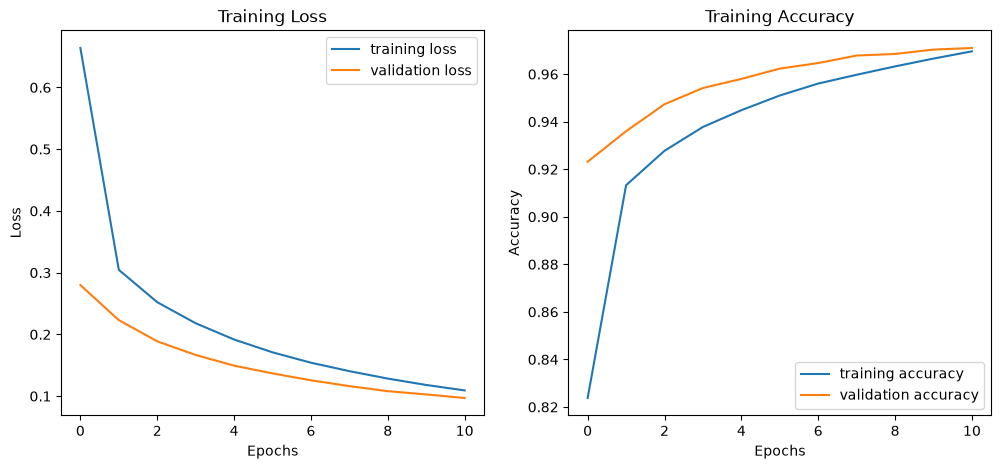

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
train = pd.read_csv('LP_IV_Updated Datasets/LP_IV_Updated Datasets/FNN and CNN/HandWritten MNIST/mnist_train.csv')
test = pd.read_csv('LP_IV_Updated Datasets/LP_IV_Updated Datasets/FNN and CNN/HandWritten MNIST/mnist_test.csv')
X_train = train.iloc[:, 1:].values
y_train = train.iloc[:, 0].values
X_test = test.iloc[:, 1:].values
y_test = test.iloc[:, 0].values
X_train = X_train / 255.0
X_test = X_test / 255.0
model = Sequential([
    Dense(128, activation='relu', input_shape=(784,)),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])
model.compile(
    optimizer='sgd',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
history = model.fit(
    X_train, y_train,
    epochs=11, batch_size=32, validation_split=0.1
)
loss, accuracy = model.evaluate(X_test, y_test)
print('Test Loss:', loss)
print('Test Accuracy:', accuracy * 100, '%')
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='training loss')
plt.plot(history.history['val_loss'], label='validation loss')
plt.title('Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='training accuracy')
plt.plot(history.history['val_accuracy'], label='validation accuracy')
plt.title('Training Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()
